In [1]:
import numpy as np 
import os
from pathlib import Path
import sys, os
import matplotlib.pyplot as plt
sys.path.append(os.path.join(os.getcwd(), '..'))

In [2]:
from utils.eda_helpers import read_csv_numeric

file_path = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_FOLDER = os.path.join(file_path, '..', 'dataset')
x_indices, x_data = read_csv_numeric(os.path.join(DATA_FOLDER, "x_train.csv"))
y_indices, y_data = read_csv_numeric(os.path.join(DATA_FOLDER, "y_train.csv"))

In [3]:
del x_indices["Id"]
del y_indices["Id"]

In [4]:
from utils.eda_helpers import clean_data
x_data = clean_data(x_data, x_indices)

In [5]:
columns_to_train = [
    "VETERAN3", "STOPSMK2", "BLIND", "WTKG3", "CHCCOPD1", "EDUCA", "_SMOKER3", 
    "CHKHEMO3", "METVL11_", "_LMTSCL1", "SEX", "_RFSEAT2", "_ASTHMS1", "_PASTRNG",
      "TOLDHI2", "CVDSTRK3", "LMTJOIN3", "_DRNKWEK", "FLUSHOT6", "_FRUITEX",
        "PA1VIGM_", "CHILDREN", "BEANDAY_", "EXERANY2", "AVEDRNK2", "_BMI5", 
        "MAXVO2_", "MARITAL", "PAMIN21_", "_VEGETEX", "CHOLCHK", "HIVTST6", 
        "_AGE80", "USEEQUIP", "DROCDY3_", "FEETCHK", "ORNGDAY_", "PAMIN11_", 
        "_MINAC21", "PAFREQ2_", "_CASTHM1", "METVL21_", "DRADVISE", "BPMEDS", 
        "_FRUTSUM", "MEDCOST", "VEGEDA1_", "PREDIAB1", "GENHLTH", "PERSDOC2", 
        "_RFHLTH", "CHCOCNCR", "_RACE_G1", "DIFFALON", "_CRACE1", "FLSHTMY2", 
        "PADUR2_", "EMPLOY1", "INCOME2", "USENOW3", "_PASTAE1", "PAFREQ1_", 
        "WTCHSALT", "DRNKANY5", "CHCSCNCR", "SXORIENT", "GRENDAY_", "MENTHLTH", 
        "MAXDRNKS", "CHCKIDNY", "PAVIG11_", "DRNK3GE5", "_TOTINDA", "MSCODE", 
        "ADDEPEV2", "QLACTLM2", "PNEUVAC3", "SMOKDAY2", "_AIDTST3", "_PAREC1", 
        "EXRACT21", "_LMTWRK1", "_LMTACT1", "STRFREQ_", "DIFFDRES", "_MRACE1", 
        "TRNSGNDR", "DIABETE3", "INSULIN", "DECIDE", "FEETCHK2", "HAVARTH3", 
        "DIABAGE2", "DOCTDIAB", "PA1MIN_", "_MINAC11", "EXRACT11", "_PACAT1", 
        "LONGWTCH", "_MISVEGN", "CHECKUP1", "DIFFWALK", "PHYSHLTH", "FRUTDA1_", 
        "FRUIT1", "SMOKE100", "PAVIG21_", "ARTHSOCL", "_PAINDX1", "PAMISS1_", 
        "BLOODCHO", "HTM4", "ALCDAY5", "RENTHOM1", "_MISFRTN", "SCNTWRK1", 
        "POORHLTH", "PADUR1_", "FC60_", "_VEGESUM", "BPHIGH4"]


In [6]:
x_train = x_data.copy()
col_means = np.nanmean(x_train, axis=0)
inds = np.where(np.isnan(x_train))
x_train[inds] = np.take(col_means, inds[1])
x_train[inds] = np.round(x_train[inds]).astype(int)
x_train

array([[0.00000e+00, 5.30000e+01, 1.10000e+01, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00],
       [1.00000e+00, 3.30000e+01, 1.20000e+01, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00],
       [2.00000e+00, 2.00000e+01, 1.00000e+01, ..., 1.00000e+00,
        2.00000e+00, 2.00000e+00],
       ...,
       [3.28132e+05, 3.90000e+01, 1.00000e+01, ..., 2.00000e+00,
        2.00000e+00, 2.00000e+00],
       [3.28133e+05, 3.30000e+01, 1.20000e+01, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00],
       [3.28134e+05, 3.20000e+01, 9.00000e+00, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00]])

In [7]:

y_data[y_data[:, 1] == -1] = 0
y_data[:, -1].sum()

28975.0

split calls: 888calls [06:59, 17.04calls/s]

Train accuracy: 0.9158791351120728


split calls: 889calls [07:10, 17.04calls/s]

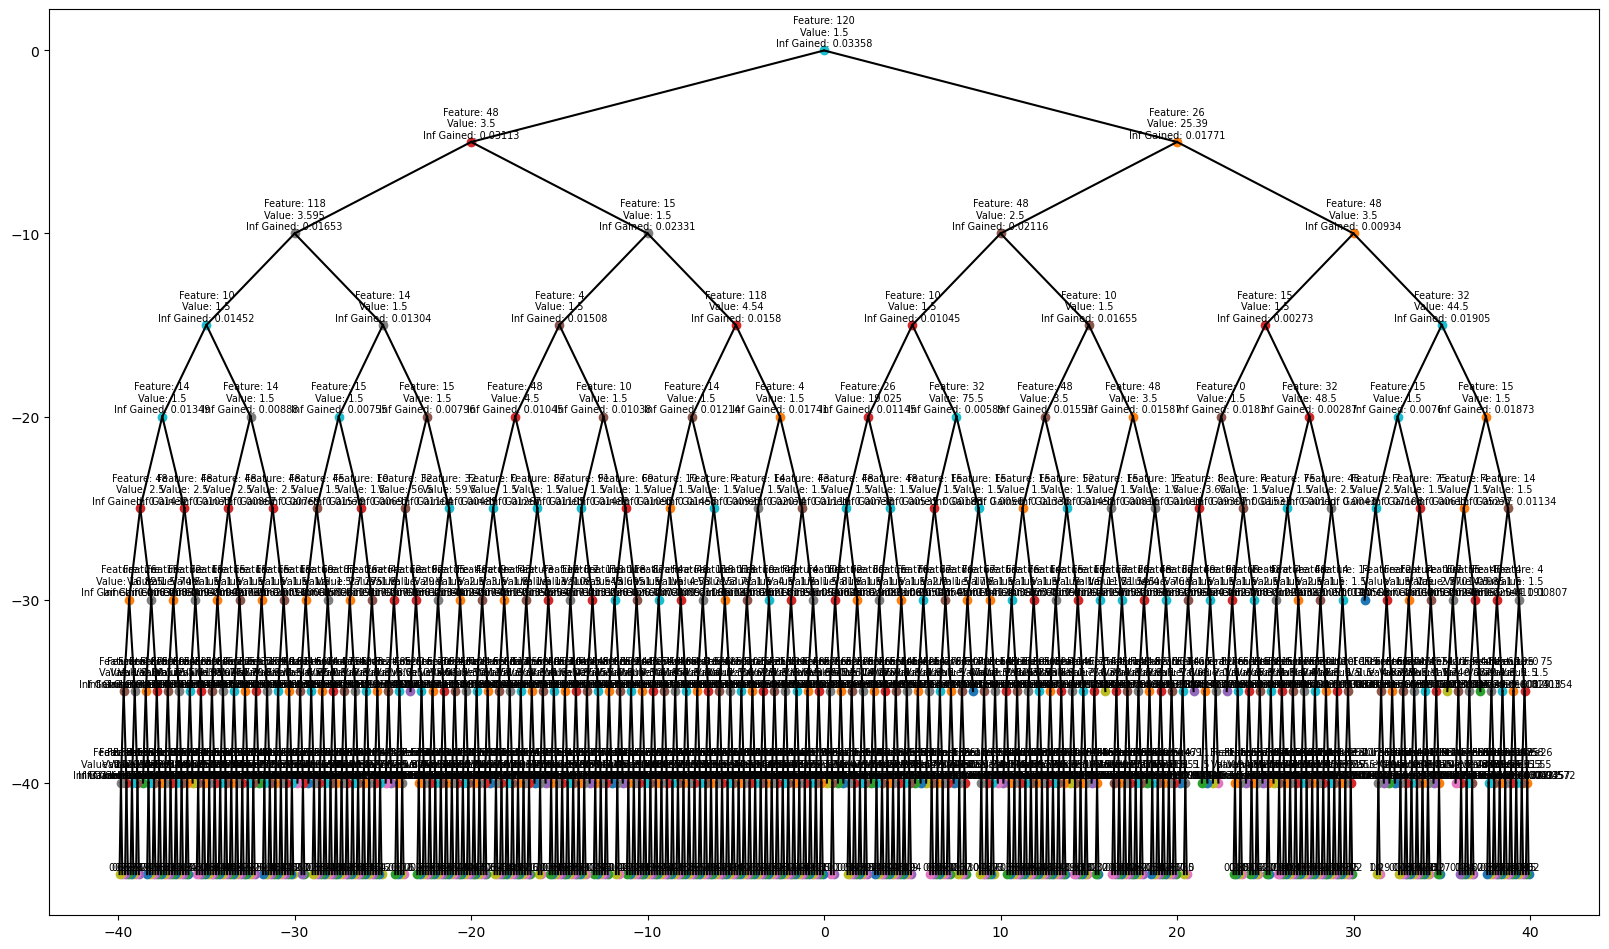

In [ ]:
import importlib
from utils.decision_tree import Decision_Tree

selected_indices = [x_indices[col] for col in columns_to_train if col in x_indices]
x_selected = x_train[:, selected_indices]

dt = Decision_Tree(maximum_depth=6, minimum_leaves=3, splitting_criterion="entropy", stopping_criterion=0.0,
                   show_split_progress=True)
dt.train(x_selected, y_data[:, 1])
preds = dt.predict(x_selected)
print("Train accuracy:", np.mean(preds == y_data[:, 1]))
dt.print_tree()

In [ ]:
from utils.decision_tree import Decision_Tree
from utils.random_forest import Random_Forest

selected_indices = [x_indices[col] for col in columns_to_train if col in x_indices]
x_selected = x_train[:, selected_indices]

rf = Random_Forest(base_learners_num=20, max_tree_depth=7, min_samples_leaf=1, 
                   min_information_gain=0, split_feature_ratio=0.25, splits_by_feature=2,
                   show_split_progress=False, split_row_ratio=0.5)

rf.train(x_selected, y_data[:, 1])
preds = rf.predict(x_selected)
print("Train accuracy:", np.mean(preds == y_data[:, 1]))
for learner in rf.base_learners:
    learner.print_tree()

Training base learner  1 / 20
Splitting on feature  120  at value  1.5


KeyboardInterrupt: 

In [ ]:
selected_indices = [x_indices[col] for col in columns_to_train if col in x_indices]
x_selected = x_train[:, selected_indices]
f = np.random.choice(x_selected.shape[1]-1, size=int((x_selected.shape[1]-1) *0.3), replace=False)
range(f)

TypeError: only integer scalar arrays can be converted to a scalar index